In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os

BASE = "/content/drive/MyDrive/gpt_project"

tok_path = os.path.join(BASE, "tokenizer", "tokenizer.json")
data_dir = os.path.join(BASE, "data", "encoded")

using device: cuda
vocab size: 5000
parameters: 19,714,560
step     0 | train loss 8.5625 | val loss 8.5623 | val perplexity 5230.64
  → saved best model (val loss 8.5623)
  step 50 | loss 6.6616
  step 100 | loss 6.2306
  step 150 | loss 5.9741
  step 200 | loss 5.8207
  step 250 | loss 5.6911
  step 300 | loss 5.5763
  step 350 | loss 5.4508
  step 400 | loss 5.3393
  step 450 | loss 5.2021
step   500 | train loss 5.1757 | val loss 5.1829 | val perplexity 178.19
  → saved best model (val loss 5.1829)
  step 500 | loss 5.1758
  step 550 | loss 5.1308
  step 600 | loss 5.0990
  step 650 | loss 4.9210
  step 700 | loss 4.9268
  step 750 | loss 4.9109
  step 800 | loss 4.7765
  step 850 | loss 4.7389
  step 900 | loss 4.6983
  step 950 | loss 4.7548
step  1000 | train loss 4.6161 | val loss 4.6493 | val perplexity 104.51
  → saved best model (val loss 4.6493)
  step 1000 | loss 4.6444
  step 1050 | loss 4.4726
  step 1100 | loss 4.4617
  step 1150 | loss 4.5520
  step 1200 | loss 4.5267


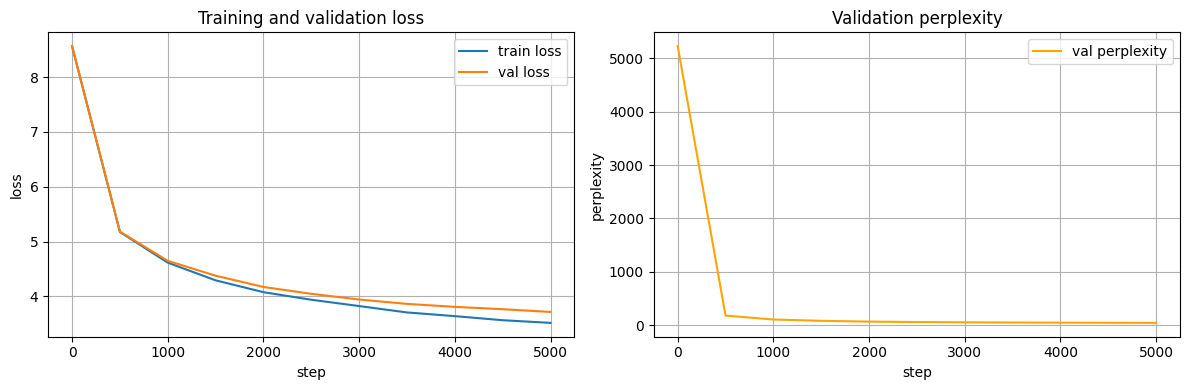

plot saved to training_curves.png
Final validation perplexity: 41.50

Generated Hindi text:
क बीर बो स ने कहा , “ आप के पास नहीं है - “ आप की मे रो पी है । इस मे रो पी पल में आप की एक प्यार है - दा श् ना मान ल के पु र् चे चु प चा प से भी प्यार


In [8]:
import os
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass
from tokenizers import Tokenizer

# ── Reproducibility ──────────────────────────────────────────────
torch.manual_seed(42)
np.random.seed(42)

# ── Device ───────────────────────────────────────────────────────
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"using device: {device}")

# ── Tokenizer ────────────────────────────────────────────────────
tok        = Tokenizer.from_file(tok_path)
VOCAB_SIZE = tok.get_vocab_size()
print(f"vocab size: {VOCAB_SIZE}")

# ── Data loading (from Task 1) ───────────────────────────────────
train_data = np.memmap("/content/drive/MyDrive/gpt_project/data/encoded/train.bin", dtype=np.uint32, mode="r")
val_data   = np.memmap("/content/drive/MyDrive/gpt_project/data/encoded/val.bin",   dtype=np.uint32, mode="r")

def get_batch(split, batch_size, block_size):
    data = train_data if split == "train" else val_data
    ix   = torch.randint(len(data) - block_size - 1, (batch_size,))
    x    = torch.stack([torch.from_numpy(data[i:i+block_size].astype(np.int64)) for i in ix])
    y    = torch.stack([torch.from_numpy(data[i+1:i+block_size+1].astype(np.int64)) for i in ix])
    return x.to(device), y.to(device)

# ── Config ───────────────────────────────────────────────────────
@dataclass
class GPTConfig:
    block_size: int = 128 #CHANGE TO 128
    vocab_size: int = VOCAB_SIZE
    n_layer:    int = 10 #INCREASE TO 12 MAYBE
    n_head:     int = 16
    n_embd:     int = 384
    # dropout:    float = 0.1 #

# ── Hyperparameters ──────────────────────────────────────────────
BATCH_SIZE    = 64
MAX_ITERS     = 5000
EVAL_ITERS    = 100
EVAL_INTERVAL = 500
LR            = 3e-4

# ── Model components ─────────────────────────────────────────────
class MultiHeadAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        # self.attn_dropout = nn.Dropout(config.dropout)
        # self.resid_dropout = nn.Dropout(config.dropout)
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        self.register_buffer(
            "mask",
            torch.tril(torch.ones(config.block_size, config.block_size))
                  .view(1, 1, config.block_size, config.block_size)
        )

    def forward(self, x):
        B, T, C = x.size()
        qkv      = self.c_attn(x)
        q, k, v  = qkv.split(self.n_embd, dim=2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(k.size(-1)))
        att = att.masked_fill(self.mask[:, :, :T, :T] == 0, float('-inf'))
        att = F.softmax(att, dim=-1)
        # att = self.attn_dropout(att)
        y   = att @ v
        y   = y.transpose(1, 2).contiguous().view(B, T, C)
        y   = self.c_proj(y)
        # y   = self.resid_dropout(y)
        return y

class FFN(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc   = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.relu   = nn.ReLU()
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)
        # self.dropout = nn.Dropout(config.dropout)

    def forward(self, x):
        x = self.c_fc(x)
        x = self.relu(x)
        x = self.c_proj(x)
        # x = self.dropout(x)
        return x

class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln1       = nn.LayerNorm(config.n_embd)
        self.attention = MultiHeadAttention(config)
        self.ln2       = nn.LayerNorm(config.n_embd)
        self.ffn       = FFN(config)           # bug fix: was `slef.ffn`

    def forward(self, x):
        x = x + self.attention(self.ln1(x))
        x = x + self.ffn(self.ln2(x))
        return x

class GPTBaseWithHead(nn.Module):
    def __init__(self, config):
        super().__init__()                     # bug fix: was `super().__init__` missing ()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            wte   = nn.Embedding(config.vocab_size, config.n_embd),
            wpe   = nn.Embedding(config.block_size, config.n_embd),
            h     = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f  = nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        # self.drop = nn.Dropout(config.dropout)
        # weight tying
        self.transformer.wte.weight = self.lm_head.weight

        # weight init
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.size()
        assert T <= self.config.block_size

        pos     = torch.arange(0, T, dtype=torch.long, device=idx.device)
        pos_emb = self.transformer.wpe(pos)
        tok_emb = self.transformer.wte(idx)
        x       = tok_emb + pos_emb
        # x = self.drop(x)

        for block in self.transformer.h:
            x = block(x)

        x      = self.transformer.ln_f(x)
        logits = self.lm_head(x)               # (B, T, vocab_size)

        loss = None
        if targets is not None:
            loss = F.cross_entropy(
                logits.view(-1, logits.size(-1)),
                targets.view(-1)
            )
        return logits, loss

# ── Instantiate model ────────────────────────────────────────────
config = GPTConfig()
model  = GPTBaseWithHead(config).to(device)
print(f"parameters: {sum(p.numel() for p in model.parameters()):,}")

optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
#  smoothly decay the LR from 3e-4 down to 1e-5 by step 5000
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=MAX_ITERS, eta_min=1e-5)
# ── Evaluation ───────────────────────────────────────────────────
@torch.no_grad()
def estimate_loss():
    model.eval()
    out = {}
    for split in ["train", "val"]:
        losses = []
        for _ in range(EVAL_ITERS):
            x, y  = get_batch(split, BATCH_SIZE, config.block_size)
            _, loss = model(x, y)
            losses.append(loss.item())
        out[split] = np.mean(losses)
    model.train()
    return out

# ── Training loop ────────────────────────────────────────────────
train_losses, val_losses, val_ppls, eval_steps = [], [], [], []

best_val_loss    = float("inf")
patience         = 3
patience_counter = 0

for step in range(MAX_ITERS):

    # eval
    if step % EVAL_INTERVAL == 0 or step == MAX_ITERS - 1:
        losses  = estimate_loss()
        val_ppl = math.exp(losses["val"])
        print(f"step {step:5d} | train loss {losses['train']:.4f} "
              f"| val loss {losses['val']:.4f} "
              f"| val perplexity {val_ppl:.2f}")

        train_losses.append(losses["train"])
        val_losses.append(losses["val"])
        val_ppls.append(val_ppl)
        eval_steps.append(step)

        # save best model + early stopping
        if losses["val"] < best_val_loss:
            best_val_loss = losses["val"]
            patience_counter = 0
            torch.save(model.state_dict(), "best_model.pt")
            print(f"  → saved best model (val loss {best_val_loss:.4f})")
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"Early stopping at step {step}")
                break

    # train step
    x, y    = get_batch("train", BATCH_SIZE, config.block_size)
    _, loss = model(x, y)
    optimizer.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()
    scheduler.step()

    if step % 50 == 0 and step > 0:
        print(f"  step {step} | loss {loss.item():.4f}", flush=True)

# ── Plots ────────────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(eval_steps, train_losses, label="train loss")
ax1.plot(eval_steps, val_losses,   label="val loss")
ax1.set_xlabel("step")
ax1.set_ylabel("loss")
ax1.set_title("Training and validation loss")
ax1.legend()
ax1.grid(True)

ax2.plot(eval_steps, val_ppls, color="orange", label="val perplexity")
ax2.set_xlabel("step")
ax2.set_ylabel("perplexity")
ax2.set_title("Validation perplexity")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.savefig("q2_training_curves.png", dpi=150)
plt.show()
print("plot saved to training_curves.png")

# ── Final perplexity ─────────────────────────────────────────────
@torch.no_grad()
def compute_perplexity(split="val"):
    model.eval()
    losses = []
    for _ in range(EVAL_ITERS):
        x, y = get_batch(split, BATCH_SIZE, config.block_size)
        _, loss = model(x, y)
        losses.append(loss.item())
    ppl = math.exp(np.mean(losses))
    print(f"Final validation perplexity: {ppl:.2f}")
    return ppl

compute_perplexity("val")

# ── Generation ───────────────────────────────────────────────────
@torch.no_grad()
def generate(model, tokenizer, prompt="", max_new_tokens=50, temperature=0.8):
    model.eval()
    torch.manual_seed(42)                      # seed for reproducible generation

    if prompt:
        ids = tokenizer.encode(prompt).ids
    else:
        ids = [tokenizer.token_to_id("<|bos|>")]

    idx = torch.tensor([ids], dtype=torch.long, device=device)

    for _ in range(max_new_tokens):
        idx_cond    = idx[:, -config.block_size:]
        logits, _   = model(idx_cond)
        logits      = logits[:, -1, :] / temperature
        probs       = F.softmax(logits, dim=-1)
        next_id     = torch.multinomial(probs, num_samples=1)
        idx         = torch.cat([idx, next_id], dim=1)

    generated_ids = idx[0].tolist()
    return tokenizer.decode(generated_ids)
# Generate the raw text
raw_text = generate(model, tok, prompt="", max_new_tokens=100, temperature=0.8)

# 4. Save to a text file
output_path = "2_generated_output.txt"
with open(output_path, "w", encoding="utf-8") as f:
    f.write(raw_text)
print(f"\nSaved generated text to {output_path}")
print("\nGenerated Hindi text:")
print(raw_text)